<a href="https://colab.research.google.com/github/nadeemaadi451-droid/nadeemaadi1128-/blob/main/MLP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The loss is high 2.35 from the previous work we have done.
So to overcome this we use some techniques.

**1- softmax initial weights to uniform**

so for this reason we simply multiply the initial weights to 0.01 or 0.1 so its value falctuate between 0 and 0.1 for all values in a row. And zero to bias or we can take a small value for bias.

**2- tanh initial weights to be in range where variance of all the data points will lie in 1**
for this we use torch.nn.init function to multiply it with with initialize weight or to initialize weights. The value obtained by gain/fain_mode.

where gain is the value depend on the function we are using relu, tanh e.t.c

fain_mode is depend on the dimension used by the variable use in function e.g the parameters.




**Normalization**
so other way to not stuck in backpropagation(for high and very low value the backpropagation will become zero depend on the function). So we normalize it.

In [3]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
words= open('/content/names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0

# Create the inverse mapping (commonly named itos for index-to-string)
itos = {i: s for s, i in stoi.items()}


In [5]:
block_size=3 # context length, how many char we take to predict next
X, Y=[],[]
for w in words:
  context= [0]*block_size
  for ch in w+('.'):
    ix=stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context= context[1:]+[ix]
X=torch.tensor(X)
Y=torch.tensor(Y)

In [6]:
from sklearn.model_selection import train_test_split

# X and Y are your features and targets
# Step 1: Split into Train (80%) and Temp (20% for dev + test combined)
X_train, X_temp, y_train, y_temp = train_test_split(X, Y, test_size=0.2, random_state=42)

# Step 2: Split Temp equally into Dev (10%) and Test (10%)
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train: {len(X_train)}, Dev: {len(X_dev)}, Test: {len(X_test)}")

Train: 182516, Dev: 22815, Test: 22815


In [7]:
C= torch.rand(27,10)
embe= C[X_train]
g=torch.Generator().manual_seed(2147483647)
C= torch.rand(27,10, generator=g)
W1= torch.rand(30,200, generator=g) * 0.2 # total neurons will be 100 and each nuron get 3 characters with 2 dimensions
b1=torch.rand(200,generator=g)* 0 # 100 nurons so 100 biases but keep in mind that during addition it will at to each rows 100
W2=torch.rand(200,27, generator=g)* 0.01
b2=torch.rand(27,generator=g) * 0
bngain=torch.ones(1,200)
bnbias=torch.zeros(1,200)

# Initialize running mean and standard deviation
bnmean_running = torch.zeros(1, 200)
bnstd_running = torch.ones(1, 200)

parameters=[C,W1,b1,W2,b2,bngain,bnbias]

In [8]:
for p in parameters:
  p.requires_grad=True

In [9]:
# Ensure all parameters have requires_grad set to True
for p in parameters:
  p.requires_grad = True

for i in range(10000):
  #minibatch
  ix=torch.randint(0,X_train.shape[0],(32,))
  # forward pass
  embb = C[X_train[ix]]
  embb = embb.view(-1, 30)
  hpreact= embb @ W1 + b1
  bnmeani=hpreact.mean(0,keepdim=True)
  bnstdi=hpreact.std(0,keepdim=True)
  # Corrected batch normalization formula
  hpreact = bngain * (hpreact - bnmeani) / (bnstdi + 1e-5) + bnbias

  # Update running statistics (no gradients needed)
  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

  h = torch.tanh(hpreact) # adding tanh activation function for the hidden layer
  # Now generate 32 neurons using softmax
  logits = h @ W2 + b2
  Loss = F.cross_entropy(logits, y_train[ix])

  # backward pass
  for p in parameters:
    p.grad = None
  Loss.backward()

  # update parameters (gradient descent: subtract the gradient)
  for p in parameters:
    p.data += -0.1 * p.grad

print(Loss.item())

2.371284246444702


In [10]:
embb = C[X_dev]
embb = embb.view(-1, 30)
h = torch.tanh(embb @ W1 + b1) # adding tanh activation function for the hidden layer
  # Now generate 32 neurons using softmax
logits = h @ W2 + b2
Loss = F.cross_entropy(logits, y_dev)
Loss


tensor(2.9060, grad_fn=<NllLossBackward0>)

**Lets try using pytorch**

In [21]:
class Linear:
  def __init__(self,fan_in,fan_out, bias=True):
    self.weight=torch.randn((fan_in,fan_out), generator=g)/(fan_in**0.5)
    self.bias =torch.zeros(fan_out) if bias else None
  def __call__(self,x):
    self.out= x @ self.weight
    if self.bias is not None:
      self.out+=self.bias
    return self.out
  def parameters(self):
    return ([self.weight] +([] if self.bias is None else [self.bias]) )
class Batchnorm1d:
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps= eps
    self.momentum= momentum
    self.training = True
    self.gamma= torch.ones(dim)
    self.beta= torch.zeros(dim)
    self.running_mean=torch.zeros(dim)
    self.running_var=torch.ones(dim)
  def __call__(self,x):
    if self.training:
      xmean= x.mean(0,keepdim=True)
      xvar=x.var(0,keepdim=True)
    else:
      xmean=self.running_mean
      xvar=self.running_var
    xhat=(x-xmean)/((xvar + self.eps)**0.5)
    self.out= self.gamma * xhat +self.beta
    if self.training:
      self.running_mean=(1-self.momentum)* self.running_mean + self.momentum * xmean
      self.running_var=(1- self.momentum)*self.running_var + self.momentum *xvar
    return self.out
  def parameters(self):
    return [self.gamma, self.beta]
class Tanh:
  def __call__(self,x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []
n_embb=10
n_hidden=100
g= torch.Generator().manual_seed(2147483647)
C= torch.rand(27,n_embb, generator=g)
layers= [Linear(fan_in=n_embb* block_size,fan_out=n_hidden, bias=False), Batchnorm1d(n_hidden), Tanh(),
Linear(fan_in=n_hidden,fan_out=100, bias=False), Batchnorm1d(100), Tanh(),
Linear(fan_in=100,fan_out=100, bias=False), Batchnorm1d(100), Tanh(),
Linear(fan_in=100,fan_out=27, bias=False), Batchnorm1d(27)]
#last layer
with torch.no_grad():
  layers[-1].gamma*=0.1
  # for all layers
  for layer in layers:
    if isinstance(layer, Linear):
      layer.weight*=5/3
      if layer.bias is not None:
        layer.bias*=0.1
  parameters= [C] + [p for layer in layers for p in layer.parameters()]
  print(sum(p.nelement() for p in parameters))
  for p in parameters:
    p.requires_grad=True

26624


In [15]:
max_steps = 20000
batch_size = 32
lossi = []

for i in range(max_steps):
  # Minibatch construction
  ix = torch.randint(0, X_train.shape[0], (batch_size,), generator=g)
  Xb, Yb = X_train[ix], y_train[ix]

  # Forward pass
  emb = C[Xb] # embed characters into vectors
  x = emb.view(emb.shape[0], -1) # flatten character channels
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, Yb)

  # Backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # Update parameters
  lr = 0.1 if i < 10000 else 0.01 # learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # Track stats
  if i % 2000 == 0:
    print(f'{i:5d}/{max_steps:5d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

print(f'Final training loss: {loss.item():.4f}')

    0/20000: 3.3228
 2000/20000: 2.3218
 4000/20000: 2.4390
 6000/20000: 2.2244
 8000/20000: 2.2801
10000/20000: 2.3717
12000/20000: 2.2771
14000/20000: 2.0756
16000/20000: 2.1172
18000/20000: 2.4321
Final training loss: 2.0325


In [17]:
@torch.no_grad()
def split_loss(split):
  x, y = {
    'train': (X_train, y_train),
    'val': (X_dev, y_dev),
    'test': (X_test, y_test)
  }[split]

  # Set layers to evaluation mode
  for layer in layers:
    if isinstance(layer, Batchnorm1d):
      layer.training = False

  # Forward pass
  emb = C[x]
  x_flat = emb.view(emb.shape[0], -1)
  for layer in layers:
    x_flat = layer(x_flat)
  loss = F.cross_entropy(x_flat, y)

  # Reset layers back to training mode
  for layer in layers:
    if isinstance(layer, Batchnorm1d):
      layer.training = True

  print(f'{split} loss: {loss.item():.4f}')

split_loss('train')
split_loss('val')

train loss: 2.1731
val loss: 2.2003


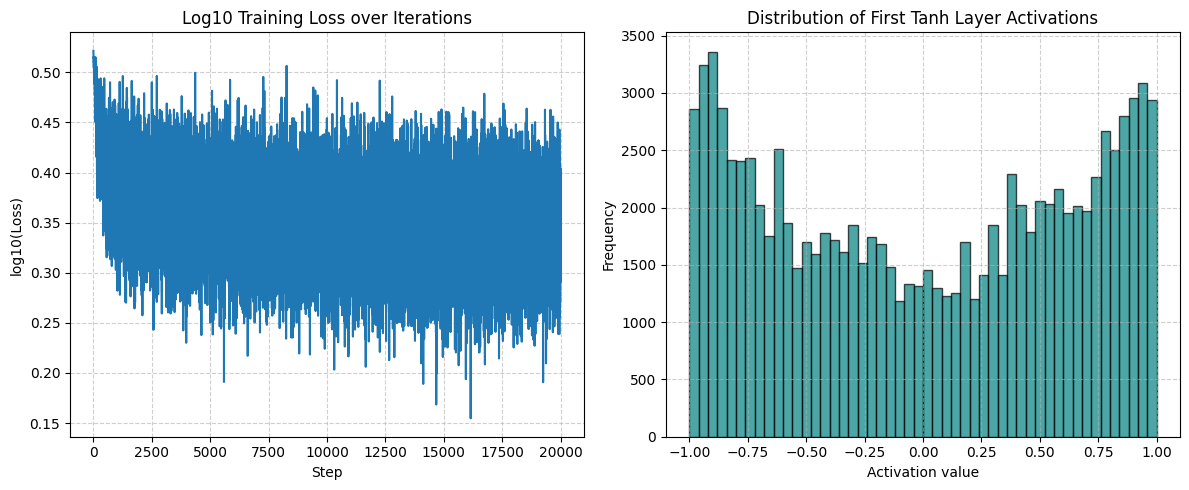

In [18]:
import numpy as np

# Plot the log loss curve
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(lossi)
plt.title('Log10 Training Loss over Iterations')
plt.xlabel('Step')
plt.ylabel('log10(Loss)')
plt.grid(True, linestyle='--', alpha=0.6)

# Visualize Tanh activation saturation on a sample training batch
with torch.no_grad():
  # Run a single batch forward pass
  ix = torch.randint(0, X_train.shape[0], (1000,))
  emb = C[X_train[ix]]
  x_act = emb.view(emb.shape[0], -1)

  # We track the activation output of the first Tanh layer (index 2 in layers)
  for j in range(3):
    x_act = layers[j](x_act)

plt.subplot(1, 2, 2)
plt.hist(x_act.view(-1).tolist(), bins=50, color='teal', edgecolor='black', alpha=0.7)
plt.title('Distribution of First Tanh Layer Activations')
plt.xlabel('Activation value')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

layer 0 (Tanh      ): mean +0.01, std 0.64, saturated: 2.56%
layer 1 (Tanh      ): mean +0.00, std 0.64, saturated: 2.84%
layer 2 (Tanh      ): mean -0.00, std 0.64, saturated: 2.41%


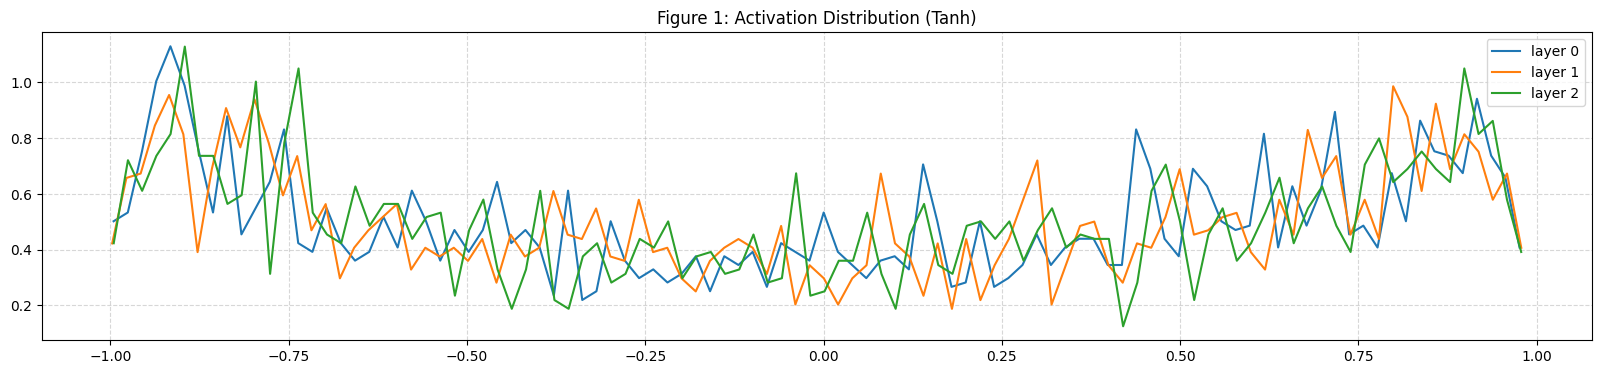

grad for layer 0 (Tanh      ): mean +0.00, std 0.00
grad for layer 1 (Tanh      ): mean -0.00, std 0.00
grad for layer 2 (Tanh      ): mean +0.00, std 0.00


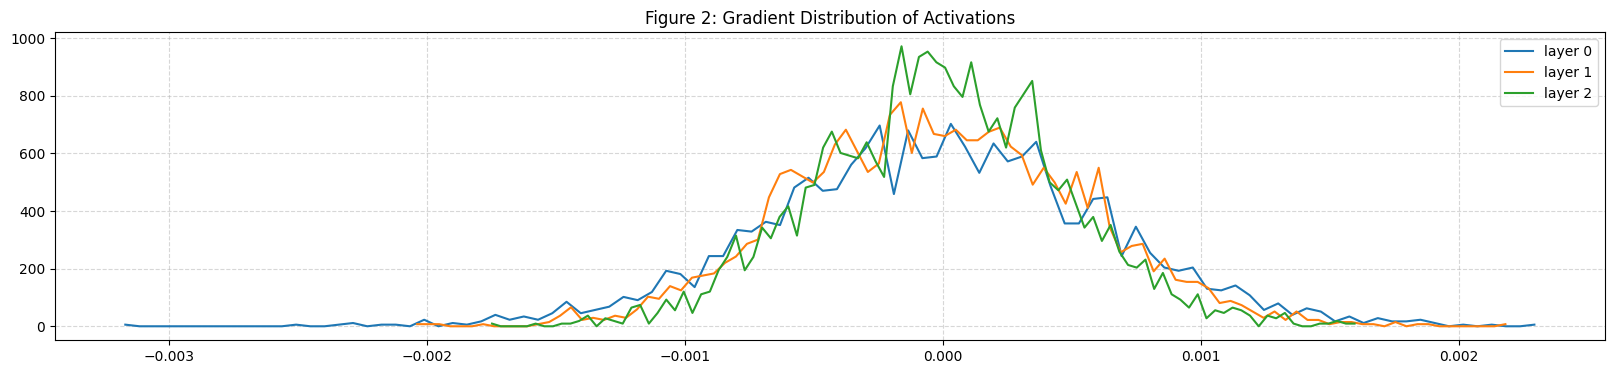

weight 0 (Linear    ): mean +0.01, std 0.31 | grad std 1.42e-03
weight 1 (Linear    ): mean -0.00, std 0.17 | grad std 1.35e-03
weight 2 (Linear    ): mean +0.00, std 0.17 | grad std 1.25e-03
weight 3 (Linear    ): mean +0.00, std 0.17 | grad std 1.93e-03


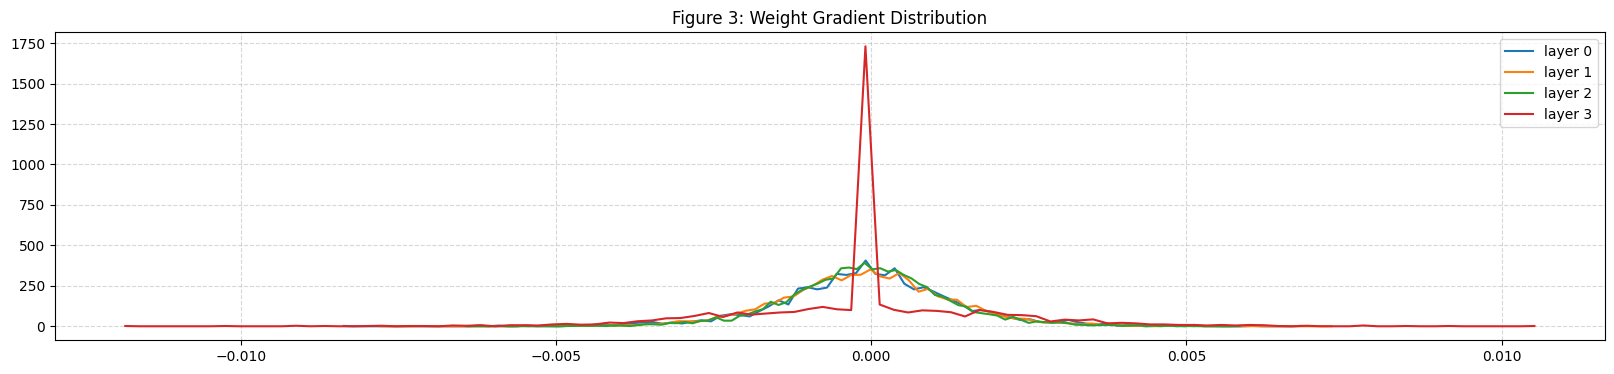

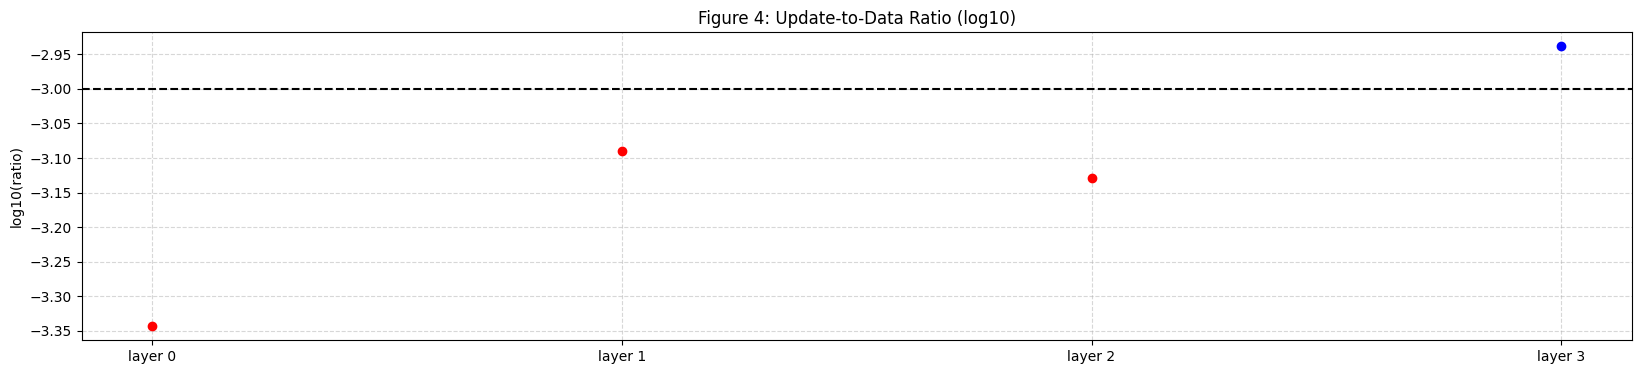

In [23]:
# 4 Diagnostic Figures (Karpathy style) to inspect Activations, Gradients, and Update Ratios
import torch
import matplotlib.pyplot as plt
%matplotlib inline

# Let's perform a forward and backward pass on a sample batch to extract fresh gradient stats
ix = torch.randint(0, X_train.shape[0], (32,))
Xb, Yb = X_train[ix], y_train[ix]

# Forward pass
emb = C[Xb]
x = emb.view(emb.shape[0], -1)
for layer in layers:
  x = layer(x)
loss = F.cross_entropy(x, Yb)

# Enable gradient tracking on activations for diagnostic plotting
for layer in layers:
  if hasattr(layer, 'out'):
    layer.out.retain_grad()

# Backward pass
for p in parameters:
  p.grad = None
loss.backward()

# Filter layers that have activations and weights to visualize
activation_layers = [layer for layer in layers if isinstance(layer, Tanh)]
weight_layers = [layer for layer in layers if isinstance(layer, Linear)]

# --- Figure 1: Activation Distributions (Tanh output histograms) ---
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(activation_layers):
  t = layer.out
  print(f'layer {i} ({layer.__class__.__name__:10s}): mean {t.mean().item():+.2f}, std {t.std().item():.2f}, saturated: {((t.abs() > 0.97).float().mean().item()*100):.2f}%')
  hy, hx = torch.histogram(t, density=True)
  plt.plot(hx[:-1].detach(), hy.detach())
  legends.append(f'layer {i}')
plt.legend(legends)
plt.title('Figure 1: Activation Distribution (Tanh)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- Figure 2: Gradient Distributions (Gradients flowing back through Tanh) ---
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(activation_layers):
  t = layer.out.grad
  print(f'grad for layer {i} ({layer.__class__.__name__:10s}): mean {t.mean().item():+.2f}, std {t.std().item():.2f}')
  hy, hx = torch.histogram(t, density=True)
  plt.plot(hx[:-1].detach(), hy.detach())
  legends.append(f'layer {i}')
plt.legend(legends)
plt.title('Figure 2: Gradient Distribution of Activations')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- Figure 3: Weight Gradient Distributions vs Weights ---
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(weight_layers):
  w = layer.weight
  print(f'weight {i} ({layer.__class__.__name__:10s}): mean {w.mean().item():+.2f}, std {w.std().item():.2f} | grad std {w.grad.std().item():.2e}')
  hy, hx = torch.histogram(w.grad, density=True)
  plt.plot(hx[:-1].detach(), hy.detach())
  legends.append(f'layer {i}')
plt.legend(legends)
plt.title('Figure 3: Weight Gradient Distribution')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- Figure 4: Update-to-Data Ratio (How fast are weights changing?) ---
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(weight_layers):
  # Update magnitude over parameter value magnitude ratio
  param_ratio = (0.1 * layer.weight.grad.std() / layer.weight.std()).log10().item()
  plt.plot([i], [param_ratio], 'ro' if param_ratio < -3 else 'bo')
  legends.append(f'layer {i}')
plt.axhline(-3, color='black', linestyle='--') # Karpathy's heuristic threshold (~1e-3 is healthy)
plt.title('Figure 4: Update-to-Data Ratio (log10)')
plt.xticks(range(len(weight_layers)), [f'layer {i}' for i in range(len(weight_layers))])
plt.ylabel('log10(ratio)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()